# 02. Segmentación clásica

## Paso 1: máscara cerebral (quitar fondo y cráneo)

1. Umbral de Otsu: separa cabeza del fondo
2. Erosión: despega el cerebro del cráneo
3. Componente conexa más grande: el cerebro
4. Dilatación: recupera el borde perdido
5. Relleno de huecos: incluye los ventrículos

In [12]:
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu

from src.io import list_scans, load, load_seg

scans = list_scans()
CASO = "sub_042"
s = next((x for x in scans if x.parent.name == CASO), scans[0])
img, zooms = load(s / "eT1W_FFE_SVR.nii.gz")
print(s.parent.name, img.shape, zooms)

sub_042 (252, 256, 250) (np.float32(1.0), np.float32(1.0), np.float32(1.0))


In [14]:
k = img.shape[2] // 2
j = img.shape[1] // 2

def show(masks, titles):
    fig, axes = plt.subplots(2, len(masks), figsize=(4 * len(masks), 8), squeeze=False)
    for c, (m, t) in enumerate(zip(masks, titles)):
        for r, sl in enumerate([lambda a: a[:, :, k], lambda a: a[:, j, :]]):
            ax = axes[r, c]
            ax.imshow(np.rot90(sl(img)), cmap="gray")
            if m is not None:
                ax.contourf(np.rot90(sl(m)), levels=[0.5, 1.5], colors=["gold"], alpha=0.4)
            ax.set_title(t if r == 0 else "", fontsize=10)
            ax.axis("off")
    plt.tight_layout()
    plt.show()

### 1. Umbral de Otsu

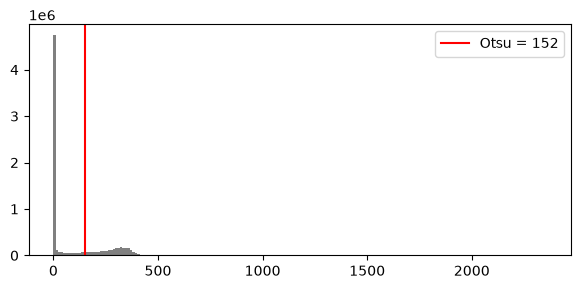

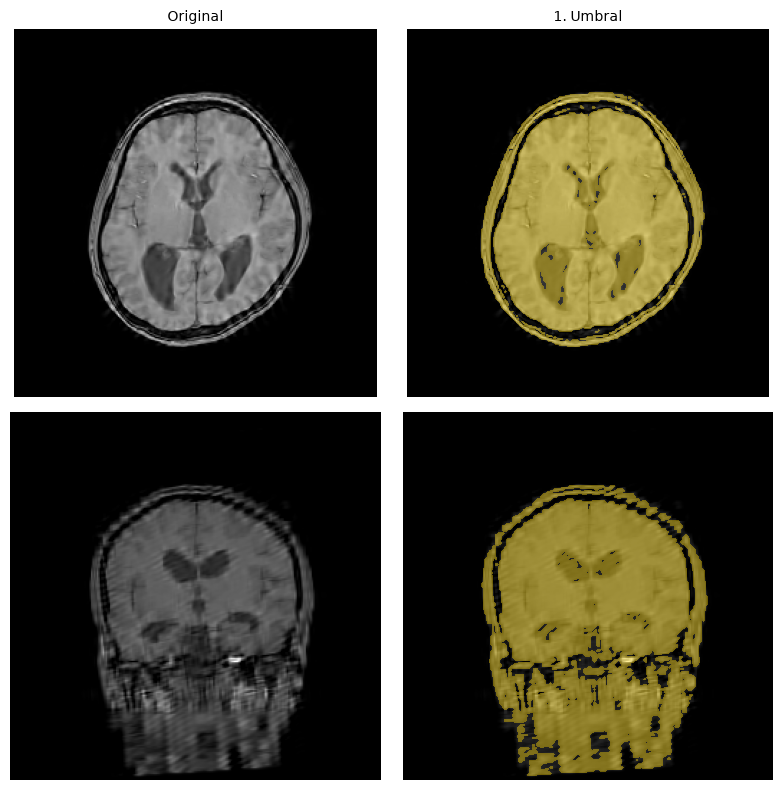

In [15]:
t = threshold_otsu(img[img > 0])
head = img > t

plt.figure(figsize=(7, 3))
plt.hist(img[img > 0].ravel(), bins=200, color="gray")
plt.axvline(t, color="red", label=f"Otsu = {t:.0f}")
plt.legend()
plt.show()

show([None, head], ["Original", "1. Umbral"])

### 2-3. Erosión y componente más grande

componentes: 286


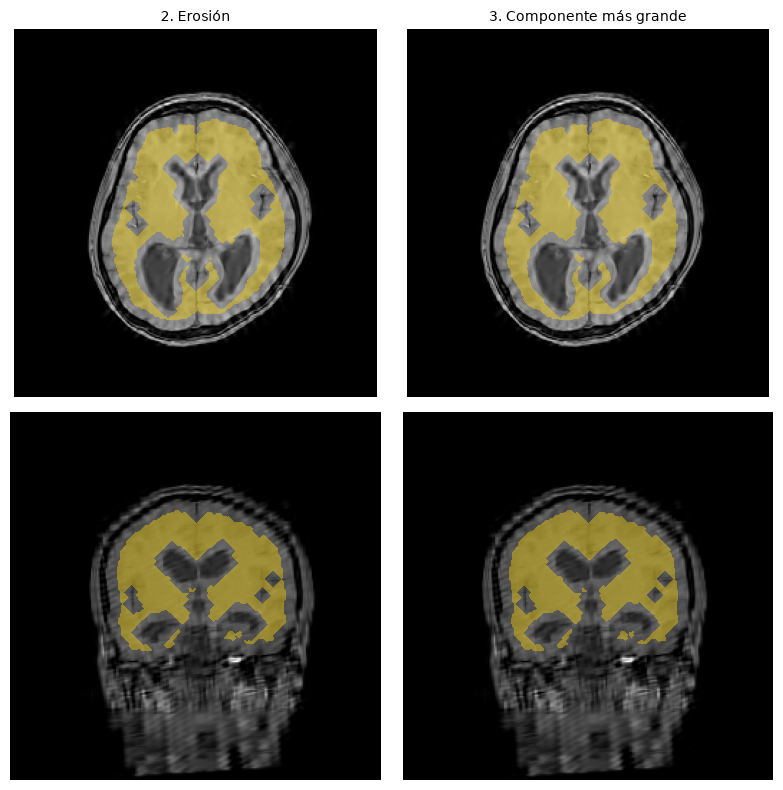

In [16]:
EROSION = 8
ball = ndi.generate_binary_structure(3, 1)

eroded = ndi.binary_erosion(head, ball, iterations=EROSION)
lab, n = ndi.label(eroded)
sizes = ndi.sum(eroded, lab, range(1, n + 1))
largest = lab == (np.argmax(sizes) + 1)
print("componentes:", n)

show([eroded, largest], ["2. Erosión", "3. Componente más grande"])

### 4-5. Dilatación y relleno

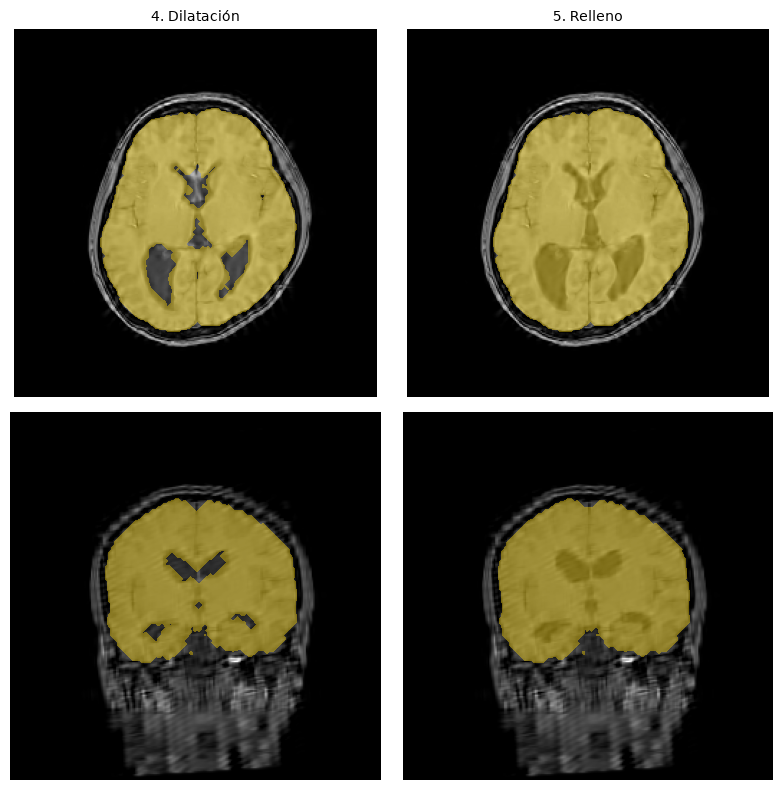

In [17]:
dilated = ndi.binary_dilation(largest, ball, iterations=EROSION) & head
brain = ndi.binary_closing(dilated, ball, iterations=3)
brain = ndi.binary_fill_holes(brain)
for z in range(brain.shape[2]):
    brain[:, :, z] = ndi.binary_fill_holes(brain[:, :, z])

show([dilated, brain], ["4. Dilatación", "5. Relleno"])

### Resultado

Dice máscara vs cerebro del experto: 0.958


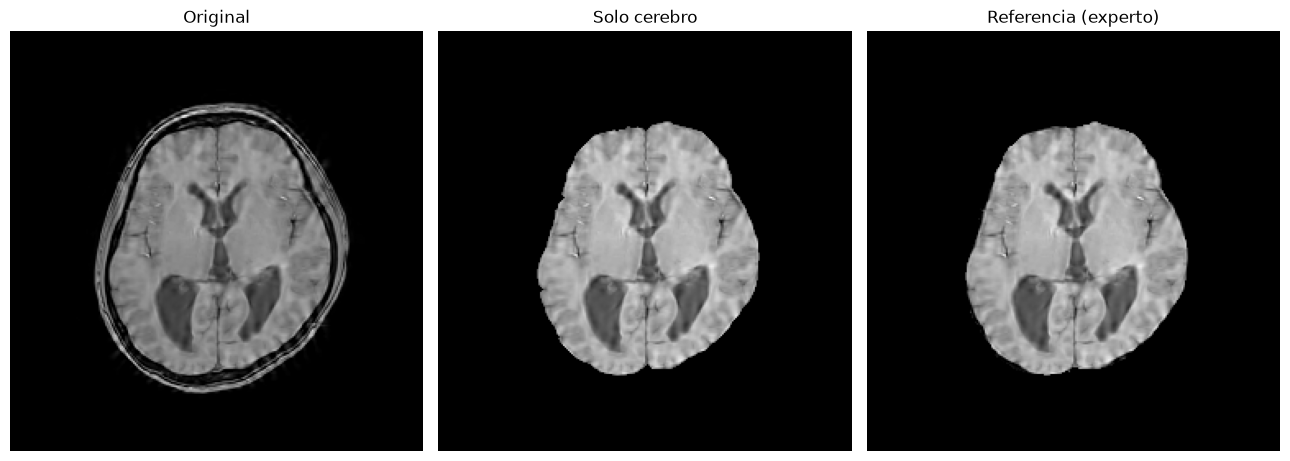

In [18]:
stripped = img * brain
gt, _ = load_seg(s / "segmentation" / "gt.nii.gz")
ref = gt > 0
for z in range(ref.shape[2]):
    ref[:, :, z] = ndi.binary_fill_holes(ref[:, :, z])
    
def dice(a, b):
    return 2 * (a & b).sum() / (a.sum() + b.sum())

print(f"Dice máscara vs cerebro del experto: {dice(brain, ref):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
for a, (v, t) in zip(ax, [(img, "Original"), (stripped, "Solo cerebro"), (ref * img, "Referencia (experto)")]):
    a.imshow(np.rot90(v[:, :, k]), cmap="gray")
    a.set_title(t)
    a.axis("off")
plt.tight_layout()
plt.show()

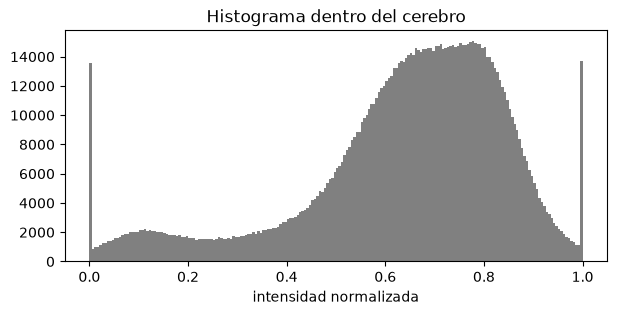

In [19]:
vals = img[brain]
lo, hi = np.percentile(vals, [1, 99])
norm = np.clip((img - lo) / (hi - lo), 0, 1) * brain

plt.figure(figsize=(7, 3))
plt.hist(norm[brain].ravel(), bins=200, color="gray")
plt.title("Histograma dentro del cerebro")
plt.xlabel("intensidad normalizada")
plt.show()

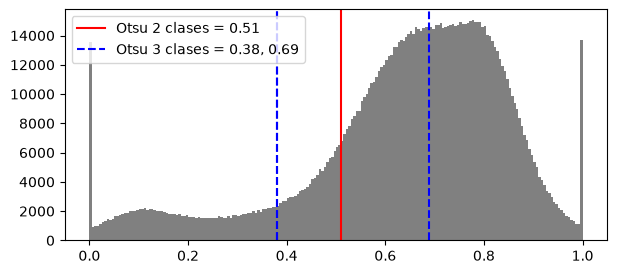

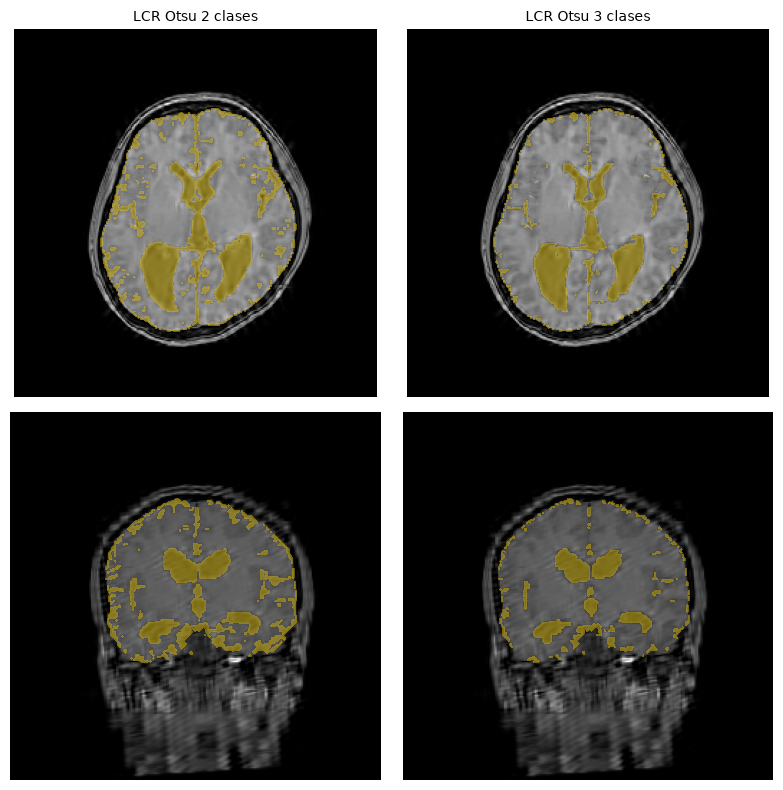

In [20]:
from skimage.filters import threshold_multiotsu

t2 = threshold_otsu(norm[brain])
t3 = threshold_multiotsu(norm[brain], classes=3)

plt.figure(figsize=(7, 3))
plt.hist(norm[brain].ravel(), bins=200, color="gray")
plt.axvline(t2, color="red", label=f"Otsu 2 clases = {t2:.2f}")
for t in t3:
    plt.axvline(t, color="blue", ls="--")
plt.axvline(t3[0], color="blue", ls="--", label=f"Otsu 3 clases = {t3[0]:.2f}, {t3[1]:.2f}")
plt.legend()
plt.show()

csf2 = (norm < t2) & brain
csf3 = (norm < t3[0]) & brain
show([csf2, csf3], ["LCR Otsu 2 clases", "LCR Otsu 3 clases"])

componentes: 79 | conservados: 1


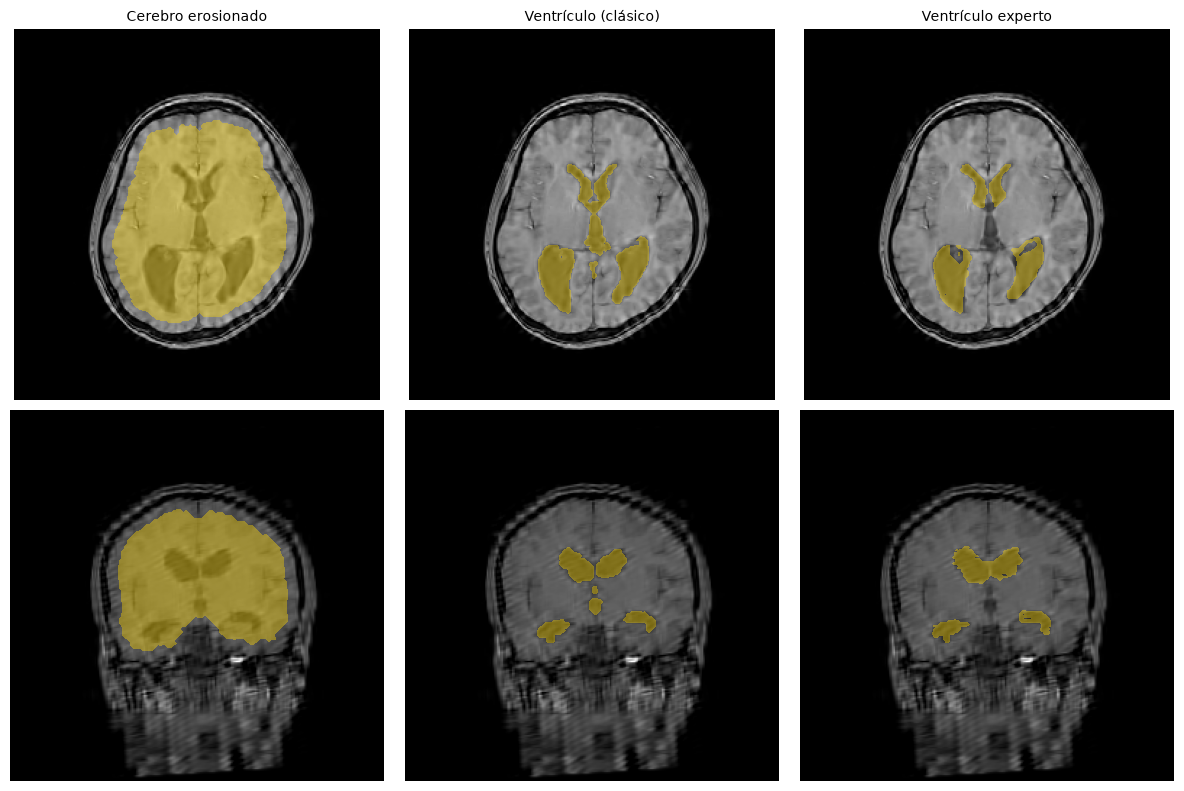

Dice ventrículo: 0.874


In [21]:
EROS_VENT = 8
inner = ndi.binary_erosion(brain, ball, iterations=EROS_VENT)
cand = csf3 & inner
cand = ndi.binary_opening(cand, ball, iterations=1)

lab, n = ndi.label(cand)
sizes = ndi.sum(cand, lab, range(1, n + 1))
center = np.array(ndi.center_of_mass(brain))
coms = np.array(ndi.center_of_mass(cand, lab, range(1, n + 1)))
dist = np.linalg.norm((coms - center) * np.array(zooms), axis=1)
keep = [i + 1 for i in range(n) if sizes[i] > 500 and dist[i] < 45]
vent = np.isin(lab, keep)
print(f"componentes: {n} | conservados: {len(keep)}")

g = np.isin(gt, [4])
show([inner, vent, g], ["Cerebro erosionado", "Ventrículo (clásico)", "Ventrículo experto"])
print(f"Dice ventrículo: {dice(vent, g):.3f}")